# Sweepset features

A sweepset is the set of sweeps of one stimulus type: long squares, short squares
or ramps. The sweepset features combine them like Allen's
`EphysCellFeatureExtractor`, e.g. the rheobase or the slope of the f-I curve. They
only need the sweep features and the first spike of each sweep, stacked into
arrays with one entry per sweep, not the traces. The examples use a cell from the [Allen Cell Types Database](https://celltypes.brain-map.org), loaded with a helper of this repository's tests. With your own recordings, all you need are NumPy arrays of time `t` (s), membrane potential `v` (mV) and, optionally, the injected current `i` (pA).

In [1]:
import sys
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

jax.config.update("jax_enable_x64", True)  # float64: results match Allen exactly

# Recordings from the Allen Cell Types Database, as downloaded for the tests
# (uv run python tests/load_testdata.py), read with a helper of the test suite.
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
sys.path.insert(0, str(REPO))

from jaxley_ephys import (  # noqa: E402
    detect_spikes,
    long_square_features,
    ramp_features,
    short_square_detection_params,
    short_square_features,
    spike_features,
    sweep_features,
)
from jaxley_ephys.cell import LONG_SQUARE_WINDOW, RAMP_START  # noqa: E402

In [2]:
from tests.utils.allen_dataset import load_specimen_case  # noqa: E402 (uses AllenSDK)

case = load_specimen_case(519832676, data_root=str(REPO / "tests/testdata/allen_cache"))

## Per-sweep features

For every sweep of a stimulus type: detect the spikes, compute the sweep features
and keep the first spike. Allen analyses long squares from 1.02 to 2.02 s, ramps
from 1.02 s and short squares from the start of the recording epoch, in each case
until the end of the sweep (`end=None`).

In [3]:
def per_sweep_features(kind, **detection):
    """Stacked sweep features and first-spike features of all sweeps of a kind."""
    sweeps, first_spikes = [], []
    for record in case.records(kind=kind):
        t, v, i, start, end = case.trace_for(record.sweep_number)
        start, end = {
            "long_square": LONG_SQUARE_WINDOW,
            "ramp": (RAMP_START, None),
        }.get(kind, (start, None))
        sp = detect_spikes(t, v, i, start, end, **detection)
        sweeps.append(sweep_features(sp, stimulus=kind))
        first_spikes.append({name: x[0] for name, x in spike_features(sp).items()})
    return stack(sweeps), stack(first_spikes)


def stack(dicts):
    """One dict of [S] arrays from S dicts of scalars."""
    return jax.tree.map(lambda *x: jnp.stack(x), *dicts)


sweeps, first_spikes = per_sweep_features("long_square")
print(f"{len(sweeps['avg_rate'])} long squares; rates (Hz): {sweeps['avg_rate']}")

14 long squares; rates (Hz): [0. 0. 0. 0. 0. 0. 0. 0. 1. 3. 4. 5. 6. 7.]


## Long squares

`long_square_features` finds the rheobase sweep, fits the f-I curve and the input
resistance, picks the sweep for the sag, averages `tau` and the baseline, and finds
the hero sweep (the lowest current from 39 to 61 pA above the rheobase).

{'rheobase_i': 130.0, 'fi_fit_slope': 0.057, 'input_resistance': 146.875, 'tau': 50.052, 'sag': 0.161, 'v_baseline': -72.548}


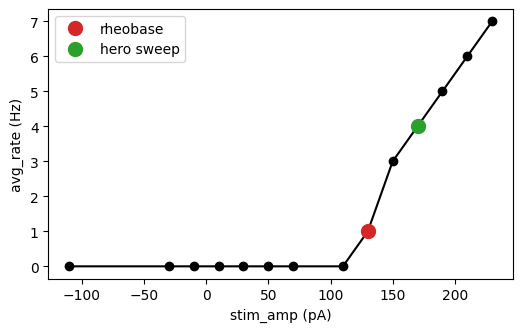

In [4]:
ls = long_square_features(sweeps, first_spikes)
names = ["rheobase_i", "fi_fit_slope", "input_resistance", "tau", "sag", "v_baseline"]
print({name: round(float(ls[name]), 3) for name in names})

amp, rate = sweeps["stim_amp"], sweeps["avg_rate"]
rheo, hero = int(ls["rheobase_index"]), int(ls["hero_index"])
plt.figure(figsize=(6, 3.5))
plt.plot(amp, rate, "ko-")
plt.plot(amp[rheo], rate[rheo], "C3o", ms=10, label="rheobase")
plt.plot(amp[hero], rate[hero], "C2o", ms=10, label="hero sweep")
plt.xlabel("stim_amp (pA)")
plt.ylabel("avg_rate (Hz)")
plt.legend()
plt.show()

## Short squares

Allen detects the spikes of short squares with adjusted parameters, estimated from
the steep passive response to the strong 3 ms pulse.
`short_square_detection_params` does the same (it needs the traces).
`short_square_features` then finds the most common amplitude that evokes spikes and
averages the first spikes of the sweeps at that amplitude.

In [5]:
traces = [case.trace_for(r.sweep_number) for r in case.records(kind="short_square")]
dv_cutoff, thresh_frac = short_square_detection_params(
    [x[0] for x in traces], [x[1] for x in traces]
)
print(f"dv_cutoff {float(dv_cutoff):.1f} V/s, thresh_frac {float(thresh_frac):.2f}")

sweeps, first_spikes = per_sweep_features(
    "short_square", dv_cutoff=dv_cutoff, thresh_frac=thresh_frac
)
ss = short_square_features(sweeps, first_spikes)
print(f"common amplitude {float(ss['stimulus_amplitude']):.0f} pA")
pd.Series({name: float(x) for name, x in ss["mean_spike_0"].items()})

dv_cutoff 12.6 V/s, thresh_frac 0.10


common amplitude 1300 pA


upstroke_downstroke_ratio      4.980603
peak_v                        46.243751
peak_t                         1.023600
trough_v                     -73.693754
trough_t                       1.211020
fast_trough_v                -47.493753
fast_trough_t                  1.026348
slow_trough_v                       NaN
slow_trough_t                       NaN
threshold_v                  -51.156252
threshold_i                  259.999999
threshold_t                    1.023048
dtype: float64

## Ramps

`ramp_features` averages the first spikes of the ramps that evoke spikes.

In [6]:
sweeps, first_spikes = per_sweep_features("ramp")
ramps = ramp_features(sweeps, first_spikes)
print("spiking ramps:", np.asarray(ramps["spiking"]))
print(f"first threshold at {float(ramps['mean_spike_0']['threshold_i']):.1f} pA")

spiking ramps: [ True  True  True]
first threshold at 221.6 pA


## Many cells at once

The sweepset features are plain JAX functions of these arrays, so they work under
`jax.vmap`: stack the features of several cells, padded to the same number of
sweeps, and mark the real sweeps with `valid`.

In [7]:
sweeps, first_spikes = per_sweep_features("long_square")
n_sweeps = len(sweeps["avg_rate"])
valid = jnp.arange(n_sweeps + 2) < n_sweeps  # two padded sweeps


def pad(x):
    return jnp.concatenate([x, x[:2]])  # any values; ignored where not valid


cells = jax.tree.map(lambda x: jnp.stack([pad(x), pad(x)]), (sweeps, first_spikes))
batched = jax.vmap(long_square_features)(*cells, jnp.stack([valid, valid]))
print("rheobase of both cells (pA):", np.round(batched["rheobase_i"], 1))

rheobase of both cells (pA): [130. 130.]
